<a href="https://colab.research.google.com/github/sushmi1202-blip/bbd-regional-performance/blob/main/Capstone_Project_1_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAPSTONE PROJECT 1

## Working with NumPy Matrices (Multidimensional Data)

### Introduction

This project focuses on analysing the National Health and Nutrition Examination Survey (NHANES) dataset using Python. It uses NumPy, Pandas, Matplotlib and Seaborn to analyse body measurements of adult male and female participants.

The project includes statistical analysis, data visualisation, BMI calculation, data standardisation and correlation analysis.


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
male_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_male_bmx_2020.csv"

female_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_female_bmx_2020.csv"

male = np.genfromtxt(male_url, delimiter=",", skip_header=1)

female = np.genfromtxt(female_url, delimiter=",", skip_header=1)

In [37]:
print("Male Dataset:")
display(male.shape)

print("Female Dataset:")
display(female.shape)

Male Dataset:


(4082, 9)

Female Dataset:


(4222, 10)

In [22]:
column_names = [
    "Weight", "Height", "Arm Circumference",
    "Arm Length", "Upper Leg Length",
    "Hip Circumference", "Waist Circumference"
]

print("Male Data:")
display(pd.DataFrame(male[:5, :7], columns=column_names))

print("Female Data:")
display(pd.DataFrame(female[:5, :7], columns=column_names))

Male Data:


,Weight,Height,Arm Circumference,Arm Length,Upper Leg Length,Hip Circumference,Waist Circumference
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,98.8,182.3,42.0,40.1,38.2,108.2,120.4
2,74.3,184.2,41.1,41.0,30.2,94.5,86.8
3,103.7,185.3,47.0,44.0,32.0,107.8,109.6
4,86.0,167.8,39.5,38.4,29.0,106.4,108.3


Female Data:


,Weight,Height,Arm Circumference,Arm Length,Upper Leg Length,Hip Circumference,Waist Circumference
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,97.1,160.2,34.7,40.8,35.8,126.1,117.9
2,91.1,152.7,33.5,33.0,38.5,125.5,103.1
3,73.0,161.2,37.4,38.0,31.8,106.2,92.0
4,61.7,157.4,38.0,34.7,29.0,101.0,90.5


## 4. Histograms of Male and Female Weights

In this section, histograms are used to visualize and compare the weight distributions of adult male and female participants. Both histograms use identical X-axis limits for a fair comparison.


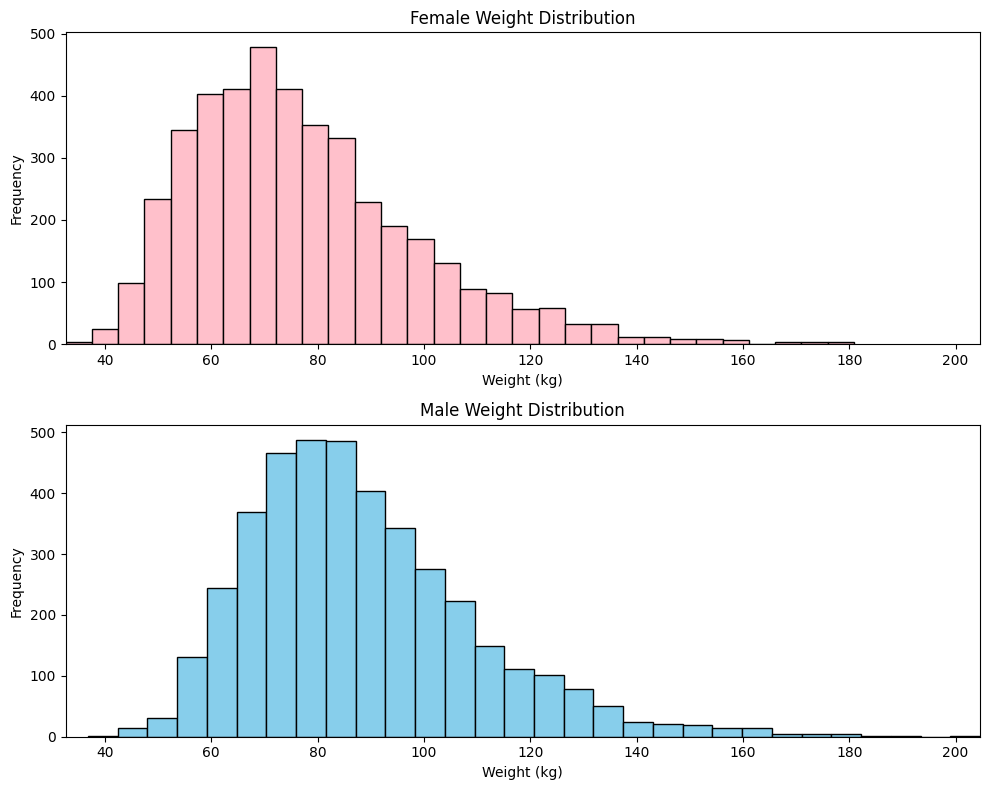

In [23]:
# Extract weight column
female_weights = female[:, 0]
male_weights = male[:, 0]

# Find common X-axis limits using nanmin and nanmax to ignore NaN values
min_weight = min(np.nanmin(female_weights), np.nanmin(male_weights))
max_weight = max(np.nanmax(female_weights), np.nanmax(male_weights))

# Create two subplots
plt.figure(figsize=(10, 8))

# Female histogram (Top)
plt.subplot(2, 1, 1)
plt.hist(female_weights[~np.isnan(female_weights)], bins=30, color='pink', edgecolor='black')
plt.title("Female Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(min_weight, max_weight)

# Male histogram (Bottom)
plt.subplot(2, 1, 2)
plt.hist(male_weights[~np.isnan(male_weights)], bins=30, color='skyblue', edgecolor='black')
plt.title("Male Weight Distribution")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")
plt.xlim(min_weight, max_weight)

plt.tight_layout()
plt.show()

### Result and Discussion

The histograms represent the weight distributions of male and female participants. The X-axis represents weight in kilograms, while the Y-axis represents frequency.

The two histograms help compare the distribution, concentration and variation of weights between males and females. Identical X-axis limits make the comparison easier and more meaningful.


## 5. Box-and-Whisker Plot of Male and Female Weights

A box-and-whisker plot is used to compare the weight distributions of male and female participants. It displays the median, quartiles, spread and outliers of the data.


/tmp/ipykernel_39424/1691478059.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


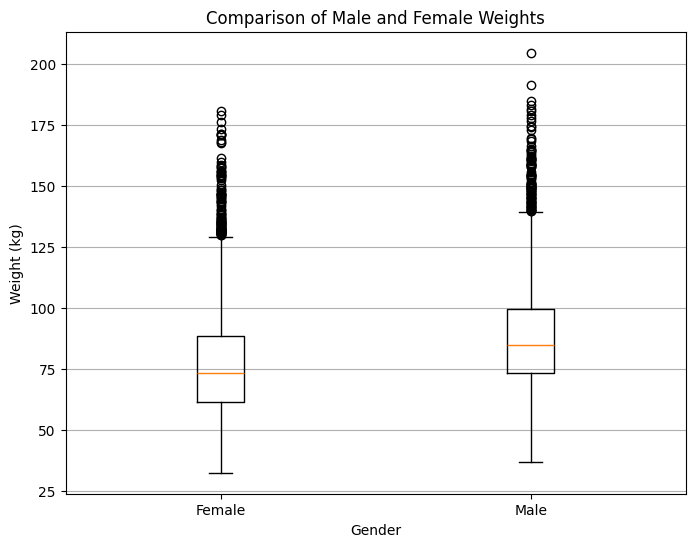

In [24]:
# Remove NaN values
female_clean = female_weights[~np.isnan(female_weights)]
male_clean = male_weights[~np.isnan(male_weights)]

# Create a boxplot
plt.figure(figsize=(8, 6))

plt.boxplot(
    [female_clean, male_clean],
    labels=['Female', 'Male']
)

plt.title("Comparison of Male and Female Weights")
plt.xlabel("Gender")
plt.ylabel("Weight (kg)")

plt.grid(axis='y')
plt.show()

### Result and Discussion

The box-and-whisker plot compares the weight distributions of male and female participants.

The median line represents the middle weight value. The box represents the interquartile range (IQR), while the whiskers indicate the spread of the data. Points beyond the whiskers represent potential outliers.

The plot helps identify differences in median weight, variation and outliers between male and female participants.


## 6. Statistical Analysis of Male and Female Weights

In this section, basic numerical aggregates are calculated for male and female weights. Measures of location, dispersion and shape are used to understand and compare the two distributions.


In [25]:
from scipy.stats import skew, kurtosis

# Remove missing values
female_clean = female_weights[~np.isnan(female_weights)]
male_clean = male_weights[~np.isnan(male_weights)]

# Function to calculate statistics
def calculate_statistics(data):
    return [
        np.mean(data),
        np.median(data),
        np.std(data),
        np.var(data),
        np.min(data),
        np.max(data),
        skew(data),
        kurtosis(data)
    ]

# Calculate statistics
female_stats = calculate_statistics(female_clean)
male_stats = calculate_statistics(male_clean)

# Display results
statistics = pd.DataFrame({
    'Measure': [
        'Mean',
        'Median',
        'Standard Deviation',
        'Variance',
        'Minimum',
        'Maximum',
        'Skewness',
        'Kurtosis'
    ],
    'Female': female_stats,
    'Male': male_stats
})

display(statistics.round(3))

,Measure,Female,Male
0,Mean,77.404,88.365
1,Median,73.600,85.000
2,Standard Deviation,21.543,21.419
3,Variance,464.080,458.771
4,Minimum,32.600,36.800
5,Maximum,180.900,204.600
6,Skewness,1.033,0.984
7,Kurtosis,1.401,1.474


### Result and Discussion

The statistical analysis provides information about the weight distributions of male and female participants.

Mean and median describe the central tendency of the data. Standard deviation and variance measure the dispersion of weights. Minimum and maximum values indicate the range of weights.

Skewness describes the asymmetry of the distributions, while kurtosis describes their tail characteristics.

These statistical measures help compare the central tendency, variability and shape of male and female weight distributions.
The statistical analysis shows that the mean weight of male participants is 88.365 kg, which is higher than the female mean weight of 77.404 kg.

The median weight is 85.000 kg for males and 73.600 kg for females. This indicates that male participants have a higher median weight.

The standard deviation is 21.419 kg for males and 21.543 kg for females. Therefore, female weights show slightly greater variation.

Both distributions have positive skewness (1.033 for females and 0.984 for males), indicating that both distributions are right-skewed.

The kurtosis values are positive for both groups, indicating heavier tails than a normal distribution.

Overall, male participants have higher average and median weights, while female participants show slightly greater variability.


## 7. Calculation of Body Mass Index (BMI)

Body Mass Index (BMI) is calculated using the weight and height of each female participant. Height is converted from centimetres to metres before calculating BMI. The calculated BMI values are added as the eighth column of the female matrix.


In [26]:
# Extract weight and height from the original 7 columns
weight = female[:, 0]
height = female[:, 1]

# Calculate BMI
bmi = weight / (height / 100) ** 2

# Add BMI as the eighth column (if not already appended)
female = np.column_stack((female[:, :7], bmi))

# Display the updated matrix
female_columns = column_names + ["BMI"]

print("Updated Female Matrix:")
display(pd.DataFrame(female[:5, :8], columns=female_columns))

print("New Shape:", female.shape)

Updated Female Matrix:


,Weight,Height,Arm Circumference,Arm Length,Upper Leg Length,Hip Circumference,Waist Circumference,BMI
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,97.1,160.2,34.7,40.8,35.8,126.1,117.9,37.835041
2,91.1,152.7,33.5,33.0,38.5,125.5,103.1,39.069720
3,73.0,161.2,37.4,38.0,31.8,106.2,92.0,28.092655
4,61.7,157.4,38.0,34.7,29.0,101.0,90.5,24.904378


New Shape: (4222, 8)


### Result and Discussion

The BMI values were calculated using the weight and height of female participants. Height was converted from centimetres to metres before applying the BMI formula.

The calculated BMI values were added as the eighth column of the female matrix. Thus, the original seven-column dataset was extended to eight columns.


## 8. Standardisation of Female Dataset Using Z-scores

In this section, all columns of the female dataset are standardised using the Z-score method. Standardisation transforms the measurements into a common scale, making comparisons between different variables easier.

A new matrix named zfemale is created without modifying the original female matrix.


In [27]:
# Calculate mean and standard deviation
mean_values = np.nanmean(female, axis=0)
std_values = np.nanstd(female, axis=0)

# Standardise all columns
zfemale = (female - mean_values) / std_values

# Display the standardised matrix
female_columns = column_names + ["BMI"]

print("Standardised Female Matrix:")
display(pd.DataFrame(zfemale[:5], columns=female_columns))

print("Shape of zfemale:", zfemale.shape)

Standardised Female Matrix:


,Weight,Height,Arm Circumference,Arm Length,Upper Leg Length,Hip Circumference,Waist Circumference,BMI
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.914295,0.008950,-0.567395,1.132988,0.550845,1.083162,1.115785,0.996968
2,0.635776,-1.053068,-1.078931,-1.293492,1.032218,1.044755,0.265089,1.156175
3,-0.204423,0.150553,0.583563,0.261944,-0.162299,-0.190647,-0.372933,-0.259275
4,-0.728968,-0.387537,0.839332,-0.764643,-0.661500,-0.523501,-0.459152,-0.670391


Shape of zfemale: (4222, 8)


In [28]:
standardisation_table = pd.DataFrame({
    "Measurement": female_columns,
    "Mean": np.nanmean(zfemale, axis=0),
    "Standard Deviation": np.nanstd(zfemale, axis=0)
})

display(standardisation_table.round(3))

,Measurement,Mean,Standard Deviation
0,Weight,0.0,1.0
1,Height,0.0,1.0
2,Arm Circumference,-0.0,1.0
3,Arm Length,-0.0,1.0
4,Upper Leg Length,0.0,1.0
5,Hip Circumference,-0.0,1.0
6,Waist Circumference,0.0,1.0
7,BMI,-0.0,1.0


### Result and Discussion

The female dataset was standardised using the Z-score method. Each column was transformed by subtracting its mean and dividing by its standard deviation.

The resulting matrix, zfemale, contains standardised values with a mean approximately equal to zero and a standard deviation approximately equal to one for each column.

Standardisation makes measurements with different units and scales suitable for comparison and further statistical analysis.


## 9. Pairplot and Correlation Analysis

In this section, a scatterplot matrix (pairplot) is created using the standardised female body measurements. Height, weight, waist circumference, hip circumference and BMI are selected for analysis.

Pearson's and Spearman's correlation coefficients are calculated to examine the relationships between all pairs of variables.


In [29]:
# Select standardised columns
selected_data = zfemale[:, [1, 0, 6, 5, 7]]

# Create a DataFrame
columns = ['Height', 'Weight', 'Waist',
           'Hip', 'BMI']

df = pd.DataFrame(selected_data, columns=columns)

# Remove missing values
df = df.dropna()

display(df.head())

,Height,Weight,Waist,Hip,BMI
1,0.008950,0.914295,1.115785,1.083162,0.996968
2,-1.053068,0.635776,0.265089,1.044755,1.156175
3,0.150553,-0.204423,-0.372933,-0.190647,-0.259275
4,-0.387537,-0.728968,-0.459152,-0.523501,-0.670391
5,-0.784024,-1.021413,-1.453546,-1.067590,-0.892899


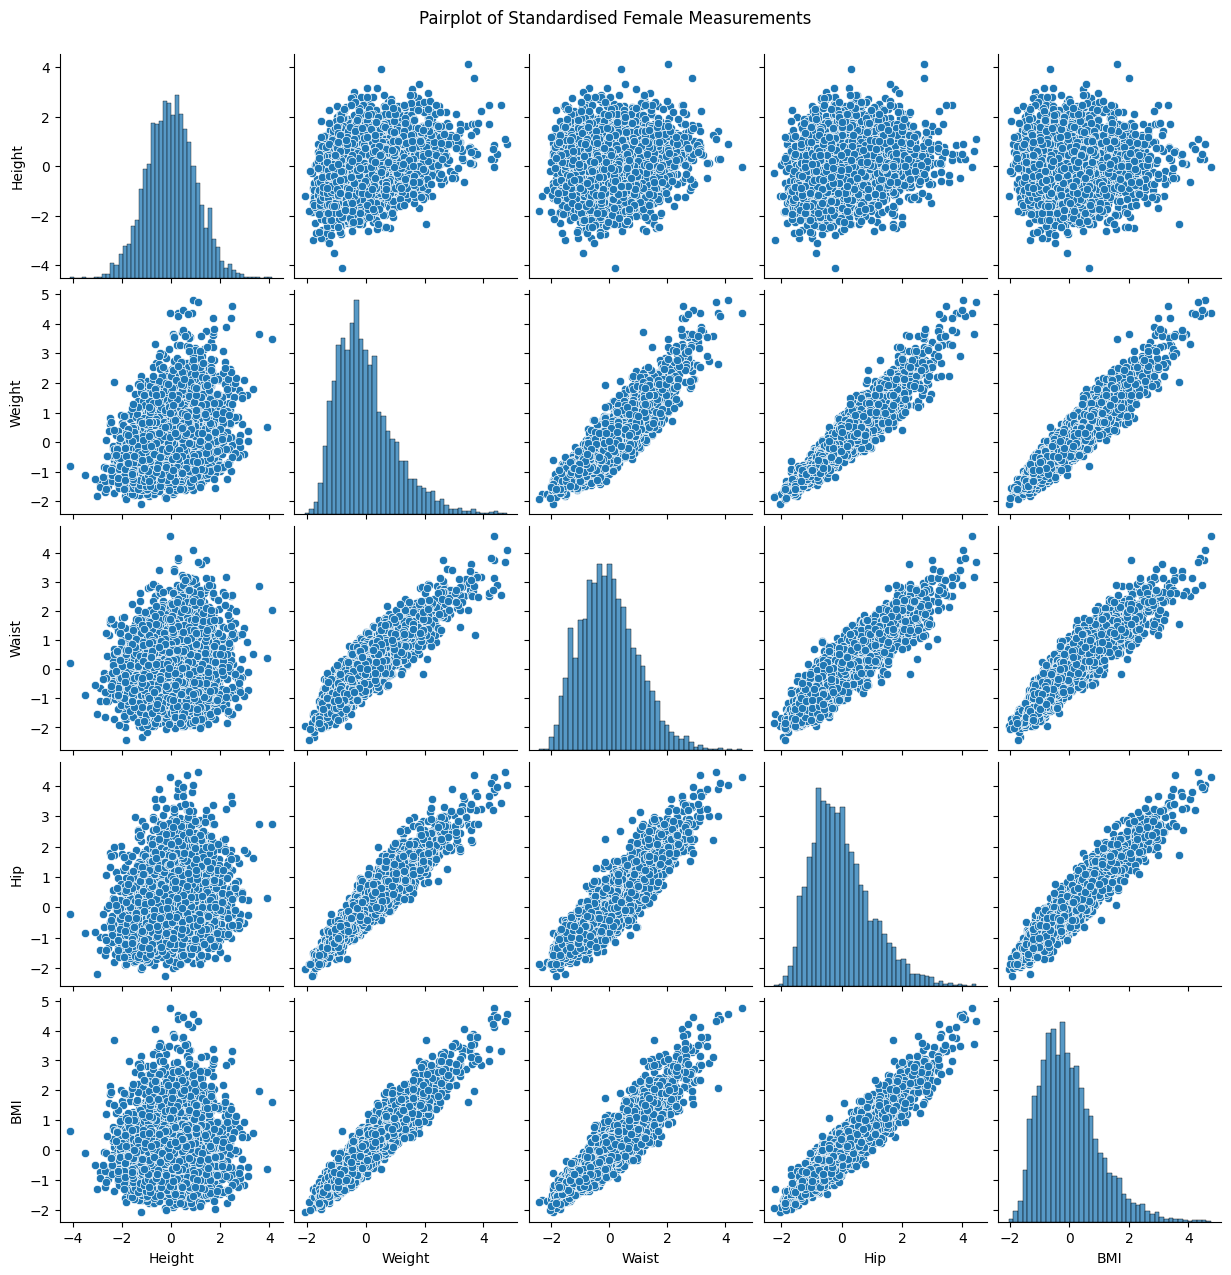

In [30]:
# Draw scatterplot matrix
sns.pairplot(df, diag_kind='hist')

plt.suptitle(
    "Pairplot of Standardised Female Measurements",
    y=1.02
)

plt.show()

In [31]:
# Calculate Pearson correlation
pearson_corr = df.corr(method='pearson')

print("Pearson Correlation Coefficients:")
display(pearson_corr.round(3))

Pearson Correlation Coefficients:


,Height,Weight,Waist,Hip,BMI
Height,1.000,0.345,0.127,0.203,0.033
Weight,0.345,1.000,0.905,0.947,0.946
Waist,0.127,0.905,1.000,0.897,0.921
Hip,0.203,0.947,0.897,1.000,0.944
BMI,0.033,0.946,0.921,0.944,1.000


In [32]:
# Calculate Spearman correlation
spearman_corr = df.corr(method='spearman')

print("Spearman Correlation Coefficients:")
display(spearman_corr.round(3))

Spearman Correlation Coefficients:


,Height,Weight,Waist,Hip,BMI
Height,1.000,0.339,0.109,0.205,0.020
Weight,0.339,1.000,0.900,0.947,0.938
Waist,0.109,0.900,1.000,0.888,0.923
Hip,0.205,0.947,0.888,1.000,0.934
BMI,0.020,0.938,0.923,0.934,1.000


### Result and Discussion

The pairplot and correlation matrices show the relationships between height, weight, waist circumference, hip circumference and BMI of female participants.

1. Height and Weight: Both Pearson (0.345) and Spearman (0.339) show a weak positive correlation.

2. Weight and Waist: Pearson (0.905) and Spearman (0.900) indicate a very strong positive correlation.

3. Weight and Hip: Both methods show a very strong positive correlation, with values of 0.947.

4. Weight and BMI: Pearson (0.946) and Spearman (0.938) indicate a very strong positive correlation.

5. Waist and BMI: Both methods show a very strong positive correlation (0.921 and 0.923).

6. Height and BMI: The correlation is very weak, with Pearson at 0.033 and Spearman at 0.020.

Overall, weight, waist circumference, hip circumference and BMI have strong positive relationships with one another. Height has comparatively weak correlations with the other measurements. Pearson and Spearman values are quite similar, suggesting that the observed relationships are largely consistent in their linear and monotonic patterns.


## 10. Calculation of Waist-to-Height and Waist-to-Hip Ratios

In this section, the waist-to-height ratio and waist-to-hip ratio are calculated for male and female participants.

These ratios are obtained using waist circumference, standing height and hip circumference. The calculated values are added as two additional columns to the male and female matrices.


In [33]:
# Calculate ratios for male participants from the original 7 columns
male_whtr = male[:, 6] / male[:, 1]
male_whr = male[:, 6] / male[:, 5]

# Reset male to original 7 columns and add the ratios
male = np.column_stack((male[:, :7], male_whtr, male_whr))

# Calculate ratios for female participants from the original columns
female_whtr = female[:, 6] / female[:, 1]
female_whr = female[:, 6] / female[:, 5]

# Reset female to first 8 columns (original 7 + BMI) and add the ratios
female = np.column_stack((female[:, :8], female_whtr, female_whr))

# Display updated matrices
male_columns = column_names + ["WHtR", "WHR"]
female_columns = column_names + ["BMI", "WHtR", "WHR"]

print("Male Matrix:")
display(pd.DataFrame(male[:5], columns=male_columns))
print("Male Shape:", male.shape)

print("\nFemale Matrix:")
display(pd.DataFrame(female[:5], columns=female_columns))
print("Female Shape:", female.shape)

Male Matrix:


,Weight,Height,Arm Circumference,Arm Length,Upper Leg Length,Hip Circumference,Waist Circumference,WHtR,WHR
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,98.8,182.3,42.0,40.1,38.2,108.2,120.4,0.660450,1.112754
2,74.3,184.2,41.1,41.0,30.2,94.5,86.8,0.471227,0.918519
3,103.7,185.3,47.0,44.0,32.0,107.8,109.6,0.591473,1.016698
4,86.0,167.8,39.5,38.4,29.0,106.4,108.3,0.645411,1.017857


Male Shape: (4082, 9)

Female Matrix:


,Weight,Height,Arm Circumference,Arm Length,Upper Leg Length,Hip Circumference,Waist Circumference,BMI,WHtR,WHR
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,97.1,160.2,34.7,40.8,35.8,126.1,117.9,37.835041,0.735955,0.934972
2,91.1,152.7,33.5,33.0,38.5,125.5,103.1,39.069720,0.675180,0.821514
3,73.0,161.2,37.4,38.0,31.8,106.2,92.0,28.092655,0.570720,0.866290
4,61.7,157.4,38.0,34.7,29.0,101.0,90.5,24.904378,0.574968,0.896040


Female Shape: (4222, 10)


### Result and Discussion

The waist-to-height ratio and waist-to-hip ratio were calculated for all male and female participants.

The waist-to-height ratio represents waist circumference relative to height, while the waist-to-hip ratio represents waist circumference relative to hip circumference.

Both calculated ratios were added as new columns to their respective matrices. The updated male matrix contains nine columns, and the female matrix contains ten columns, including BMI.


## 11. Comparison of Waist Ratios Using Boxplots

Boxplots are used to compare the distribution, median, spread and outliers of the calculated ratios.

The four distributions are:

Male WHtR

Female WHtR

Male WHR

Female WHR

/tmp/ipykernel_39424/3257889916.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


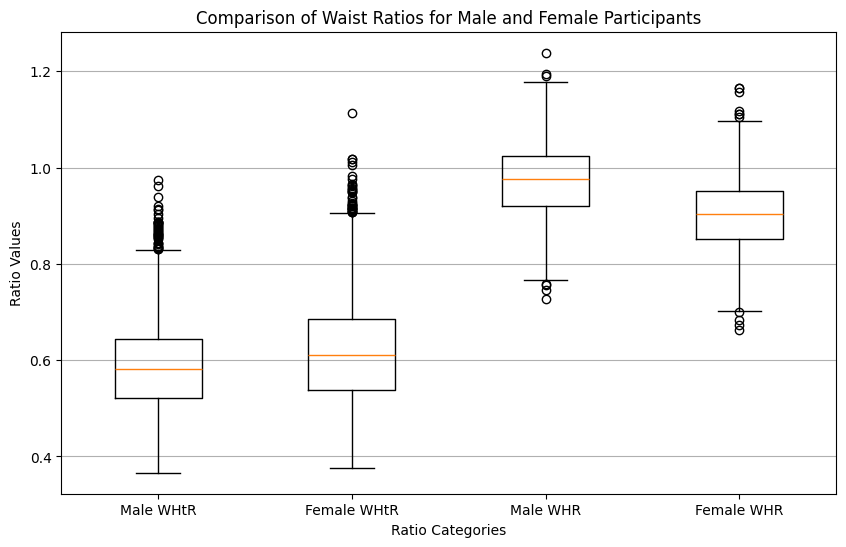

In [34]:
# Extract and remove missing values from the ratios

male_whtr_clean = male[:, 7][~np.isnan(male[:, 7])]
female_whtr_clean = female[:, 8][~np.isnan(female[:, 8])]

male_whr_clean = male[:, 8][~np.isnan(male[:, 8])]
female_whr_clean = female[:, 9][~np.isnan(female[:, 9])]


# Create boxplots
plt.figure(figsize=(10, 6))

plt.boxplot(
    [male_whtr_clean, female_whtr_clean,
     male_whr_clean, female_whr_clean],
    labels=['Male WHtR', 'Female WHtR',
            'Male WHR', 'Female WHR']
)

plt.title("Comparison of Waist Ratios for Male and Female Participants")
plt.xlabel("Ratio Categories")
plt.ylabel("Ratio Values")
plt.grid(axis='y')
plt.show()

### Result and Discussion

The boxplots compare the Waist-to-Height Ratio (WHtR) and Waist-to-Hip Ratio (WHR) distributions of male and female participants.

The median line represents the middle value of each distribution. The box represents the interquartile range, while the whiskers show the spread of the data. Individual points beyond the whiskers indicate possible outliers.

The boxplots help identify differences in the median, variability and distribution of the four calculated ratios.

## 12. Advantages and Disadvantages of BMI, WHtR and WHR

### 1. Body Mass Index (BMI)

**Advantages:**

* Easy to calculate using height and weight.
* Simple and inexpensive measurement.
* Useful for population-level screening.

**Disadvantages:**

* Does not directly measure body fat.
* Does not distinguish between muscle and fat.
* Does not show fat distribution.

### 2. Waist-to-Height Ratio (WHtR)

**Advantages:**

* Considers waist circumference relative to height.
* Simple to calculate.
* Provides information about abdominal fat distribution.

**Disadvantages:**

* Requires accurate waist and height measurements.
* Measurement methods may affect the result.
* Should not be used alone to assess individual health.

### 3. Waist-to-Hip Ratio (WHR)

**Advantages:**

* Easy to calculate using waist and hip circumference.
* Provides information about body fat distribution.
* Useful in population-level health studies.

**Disadvantages:**

* Requires two accurate circumference measurements.
* Can vary depending on measurement technique.
* Does not directly measure total body fat.


### Result and Discussion

BMI, WHtR and WHR are three commonly used measurements for studying body size and fat distribution.

BMI is calculated using height and weight, whereas WHtR and WHR use waist circumference in relation to height and hip circumference, respectively.

Each measurement has its own advantages and limitations. Therefore, no single measurement provides a complete assessment of an individual's health. These measurements are best understood as screening or research tools rather than individual diagnoses.


## 13. Identification of Participants with the 5 Lowest and 5 Highest BMI

In this section, NumPy's `argsort()` function is used to arrange female participants according to their BMI values.

The five participants with the lowest BMI and the five participants with the highest BMI are selected.

Their standardised body measurements are displayed using the `zfemale` matrix.


In [38]:
# Find valid BMI values
valid_indices = np.where(~np.isnan(bmi))[0]

# Sort participants according to BMI
sorted_indices = valid_indices[np.argsort(bmi[valid_indices])]

# Select 5 lowest and 5 highest BMI participants
lowest_indices = sorted_indices[:5]
highest_indices = sorted_indices[-5:]

# Combine selected indices
selected_indices = np.concatenate(
    (lowest_indices, highest_indices)
)

# Create a table of selected participants
selected_measurements = pd.DataFrame(
    zfemale[selected_indices],
    columns=female_columns[:8]
)

selected_measurements.insert(
    0, "Participant Index", selected_indices
)

print("Standardised Measurements:")
display(selected_measurements.round(3))

# Create a separate BMI table
categories = ["Lowest BMI"] * 5 + ["Highest BMI"] * 5

bmi_table = pd.DataFrame({
    "Category": categories,
    "Participant Index": selected_indices,
    "BMI": bmi[selected_indices]
})

print("\nSelected BMI Values:")
display(bmi_table.round(3))

Standardised Measurements:


,Participant Index,Weight,Height,Arm Circumference,Arm Length,Upper Leg Length,Hip Circumference,Waist Circumference,BMI
0,263,-2.080,-1.223,-1.548,-1.169,-2.195,-2.041,-1.942,-2.050
1,3479,-1.880,-0.189,-1.718,0.386,-2.444,-1.855,-2.057,-1.995
2,2127,-1.537,1.807,0.626,0.573,-2.266,-1.676,-1.706,-1.971
3,2754,-1.843,-0.260,-0.226,0.511,-2.302,-2.252,-1.856,-1.942
4,1210,-1.611,0.887,-0.098,0.480,-2.213,-1.829,-1.712,-1.893
5,2269,4.247,0.292,1.862,-0.982,2.369,4.104,3.817,4.396
6,3023,4.456,0.505,1.692,-1.138,3.350,3.983,2.903,4.462
7,1473,4.349,0.278,2.843,1.942,4.366,3.919,3.754,4.515
8,1105,4.804,0.887,2.118,1.817,3.778,4.021,4.082,4.543
9,1097,4.363,-0.034,-0.056,-0.174,2.779,4.316,4.570,4.762



Selected BMI Values:


,Category,Participant Index,BMI
0,Lowest BMI,263,14.203
1,Lowest BMI,3479,14.633
2,Lowest BMI,2127,14.819
3,Lowest BMI,2754,15.045
4,Lowest BMI,1210,15.421
5,Highest BMI,2269,64.199
6,Highest BMI,3023,64.707
7,Highest BMI,1473,65.115
8,Highest BMI,1105,65.333
9,Highest BMI,1097,67.037


### Result and Discussion

The `argsort()` function was used to arrange female participants according to their BMI values.

The five participants with the lowest BMI and the five participants with the highest BMI were selected.

Their standardised body measurements were displayed using the `zfemale` matrix.

This comparison helps examine how height, weight, waist circumference, hip circumference and other measurements vary among the selected participants.


# **CONCLUSION**

This project analysed the NHANES male and female datasets using Python libraries such as NumPy, Pandas, Matplotlib and Seaborn. Statistical analysis and visualisation techniques were used to compare body weight distributions. BMI, waist-to-height ratio and waist-to-hip ratio were calculated to study body measurements. Z-score standardisation and correlation analysis helped understand relationships between different variables. Finally, `argsort()` was used to identify participants with the five lowest and five highest BMI values.

Overall, this project provided practical experience in numerical computing, data analysis, statistical methods and data visualisation using Python.
